In [1]:
# Import libraries and set directories 

import numpy as np, pandas as pd
from pathlib import Path
from scipy import stats
import matplotlib.pyplot as plt

SEED = 12345
np.random.seed(SEED); rng = np.random.default_rng(SEED)

DATA = Path("mini-atlas/data"); QC = Path("results/QC"); MORPH = Path("results/morphology")
OUT = Path("results/models"); FIGS = Path("results/models/figures")

# 1. Model functions
As previously set in notebook 03 

In [2]:
# Create a design matrix for one RNA family
def design(cov, min_batch=5):
    """Build covariates for one RNA family."""

    # Add an intercept (baseline)
    X = pd.DataFrame({"intercept": 1.0}, index=cov.index)

    # Standardise continuous technical covariates
    for c in ["log10_ngenes", "intron_frac", "norm_depth"]:
        v = cov[c]
        X[c] = (v - v.mean()) / v.std(ddof=0)

    # Combine batches with fewer than min_batch cells into a "rare" category 
    b = cov["batch"].where(
        cov["batch"].map(cov["batch"].value_counts()) >= min_batch,
        "rare"
    )

    # Encode batches as dummy variables, omitting the reference category
    X = pd.concat([
        X,
        pd.get_dummies(b, prefix="batch", drop_first=True, dtype=float)
    ], axis=1)

    # Return the design matrix
    return X

def fit_family(Y, X, x, clusters):
    """Slope of every gene (columns of Y) on axis x, adjusting for covariates X,
    with standard errors clustered by mouse (CR1)."""
    Q, _ = np.linalg.qr(X)                       # orthonormal basis of the covariates
    Yr = Y - Q @ (Q.T @ Y)                       # expression with covariates removed
    xr = x - Q @ (Q.T @ x)                       # axis with covariates removed
    sxx = xr @ xr
    beta = xr @ Yr / sxx                         # slope per gene
    resid = Yr - np.outer(xr, beta)

    order = np.argsort(clusters, kind="stable")
    starts = np.r_[0, np.flatnonzero(np.diff(clusters[order])) + 1]
    scores = np.add.reduceat((xr[:, None] * resid)[order], starts, axis=0)   # summed within each mouse
    G, n, k = len(starts), X.shape[0], X.shape[1]
    correction = G / (G - 1) * (n - 1) / (n - k - 1)
    se = np.sqrt(correction * (scores ** 2).sum(0)) / abs(sxx)
    return beta, se

def meta(beta_df, se_df):
    B, S = beta_df.values, se_df.values
    w = np.where(np.isfinite(S), 1 / S ** 2, 0.0)            # precision weights, 0 where the gene wasn't fitted
    n_fam = (w > 0).sum(1)
    sw = w.sum(1)
    est = (w * np.nan_to_num(B)).sum(1) / sw
    se_m = 1 / np.sqrt(sw)
    Q = (w * (np.nan_to_num(B) - est[:, None]) ** 2).sum(1)   # Cochran's Q
    het_p = stats.chi2.sf(Q, np.maximum(n_fam - 1, 1))
    z = est / se_m
    return pd.DataFrame({"beta": est, "se": se_m, "z": z, "n_families": n_fam, "het_p": het_p},
                        index=beta_df.index)

# 1. Load data and observations 

In [3]:
# Cell metadata and QC covariates saved in notebook 01 (batch read as text, not a number)
covars = pd.read_csv(QC / "covars.csv", index_col=0, dtype={"batch": str})

# Raw exon counts (genes x cells) from the mini-atlas repo
exon = pd.read_csv(DATA / "m1_patchseq_exon_counts.csv.gz", index_col=0)

In [4]:
# Keep the QC-passed cells and flip to cells x genes
counts = exon[covars.index].T

# Normalise counts per million, then log2(x + 1), same as notebook 01
expr = np.log2(counts.div(counts.sum(axis=1), axis=0) * 1e6 + 1)

# Check genes have at least one read in each cell (used for the detection filter)
detected = counts > 0

In [5]:
# Load morphology axes from notebook 02 
pcs = pd.read_csv(MORPH / "morph_pcs.csv", index_col=0) 

# Keep only cells that have both expression and morphology (603)
cells = covars.index.intersection(pcs.index)
covars, pcs, expr, detected = covars.loc[cells], pcs.loc[cells], expr.loc[cells], detected.loc[cells]

In [6]:
# Observed results from notebook 03 (gene x axis tests), to compare against the permutation null
res = pd.read_csv(OUT / "meta_results.csv", index_col=0)

# Check: should be 603 cells and 55,736 observed tests
print(len(cells), "cells |", expr.shape[1], "genes |", len(res), "observed tests")
res.head(3)

603 cells | 42466 genes | 55736 observed tests


,beta,se,z,n_families,het_p,axis,beta_IT,beta_Pvalb,beta_Sst,beta_CT,beta_Vip,beta_Lamp5,beta_ET,p,q
gene,,,,,,,,,,,,,,,
0610009B22Rik,-0.159195,0.114594,-1.389204,7,0.574043,wPC1,-0.097285,-0.095820,-0.616741,-0.368155,-0.002352,0.161490,-1.317173,0.164771,0.754875
0610010F05Rik,0.008448,0.131931,0.064033,7,0.363949,wPC1,0.550876,-0.084346,0.240562,-0.862923,-0.015594,-0.537194,0.015461,0.948944,0.994093
0610012G03Rik,0.227132,0.125868,1.804531,7,0.142443,wPC1,1.019002,0.142395,-0.275461,0.110100,-0.038458,0.172103,-0.436121,0.071148,0.637592


# 2. Families and gene filter 
Same settings as notebook 3: families with at least 30 cells, genes detected in at least 20% of a family's cells and passing in at least 2 families. 

In [7]:
# Detection in at least 20% of families cells 
MIN_DET = 0.20

# Families in the same order as the beta_<family> columns of the observed results
strata = [c.replace("beta_", "") for c in res.columns if c.startswith("beta_")]

# Gene filter: detected in >=20% of a family's cells; keep genes that pass in >=2 families
passes = pd.DataFrame({s: detected.loc[covars.index[covars.rna_family == s]].mean() >= MIN_DET for s in strata})
universe = passes.index[passes.sum(axis=1) >= 2]

print(strata)
print("genes in universe:", len(universe), "(notebook 3: 13,934)")

['IT', 'Pvalb', 'Sst', 'CT', 'Vip', 'Lamp5', 'ET']
genes in universe: 13934 (notebook 3: 13,934)


# 3. Precompute each families' covariate-adjusted expression 

In [8]:
fam = {}
for s in strata:
    idx = covars.index[covars.rna_family == s]
    genes_s = universe[passes.loc[universe, s].values]              # genes tested in this family
    X = design(covars.loc[idx])                                     # intercept, QC/depth covariates, batch dummies
    Q, _ = np.linalg.qr(X.values)
    Y = expr.loc[idx, genes_s].values
    clusters = pd.factorize(covars.loc[idx, "mouse"])[0]            # mouse id for clustered SEs
    order = np.argsort(clusters, kind="stable")
    fam[s] = {"idx": idx,
              "pos": universe.get_indexer(genes_s),                 # where this family's genes sit in the universe
              "Q": Q,
              "Yr": Y - Q @ (Q.T @ Y),                              # expression with covariates removed
              "order": order,
              "starts": np.r_[0, np.flatnonzero(np.diff(clusters[order])) + 1],
              "k": X.shape[1]}
    print(f"{s:6s} cells={len(idx):3d} genes={len(genes_s):5d} mice={len(fam[s]['starts']):3d} covariates={X.shape[1]}")

IT     cells=150 genes=13026 mice= 91 covariates=14
Pvalb  cells=142 genes=12052 mice= 79 covariates=13
Sst    cells=101 genes=11348 mice= 47 covariates=11
CT     cells= 67 genes=11316 mice= 44 covariates=7
Vip    cells= 59 genes=10921 mice= 33 covariates=7
Lamp5  cells= 45 genes=11336 mice= 37 covariates=7
ET     cells= 33 genes=13446 mice= 23 covariates=6


# 4. Fast fit for one axis 

In [9]:
# Slope per gene and mouse-clustered SE (same maths as `fit_family`), then the meta-analysis across families.

def fit_fast(f, x):
    """Per-gene slope on x within one family, using the precomputed covariate-adjusted expression."""
    xr = x - f["Q"] @ (f["Q"].T @ x)
    sxx = xr @ xr
    beta = xr @ f["Yr"] / sxx
    resid = f["Yr"] - np.outer(xr, beta)
    scores = np.add.reduceat((xr[:, None] * resid)[f["order"]], f["starts"], axis=0)
    G, n, k = len(f["starts"]), f["Yr"].shape[0], f["k"]
    se = np.sqrt(G / (G - 1) * (n - 1) / (n - k - 1) * (scores ** 2).sum(0)) / abs(sxx)
    return beta, se


def run_axis(xdict):
    """xdict: family -> morphology values for that family's cells. Returns the meta-analysis table over all genes."""
    B = np.full((len(universe), len(strata)), np.nan)
    S = np.full_like(B, np.nan)
    for j, s in enumerate(strata):
        B[fam[s]["pos"], j], S[fam[s]["pos"], j] = fit_fast(fam[s], xdict[s])
    return meta(pd.DataFrame(B, index=universe, columns=strata),
                pd.DataFrame(S, index=universe, columns=strata))

In [10]:
# Sanity check - reproduce observed results 

axes = ["wPC1", "wPC2", "wPC3", "wPC4"]

def observed_x(axis):
    return {s: pcs.loc[fam[s]["idx"], axis].values for s in strata}

for a in axes:
    mine = run_axis(observed_x(a))
    ref = res[res.axis == a].loc[universe]
    print(f"{a}: max |beta diff| = {np.abs(mine.beta - ref.beta).max():.1e}   max |z diff| = {np.abs(mine.z - ref.z).max():.1e}")

wPC1: max |beta diff| = 1.1e-16   max |z diff| = 4.4e-16
wPC2: max |beta diff| = 2.2e-16   max |z diff| = 4.4e-16
wPC3: max |beta diff| = 2.2e-16   max |z diff| = 4.4e-16
wPC4: max |beta diff| = 1.0e-16   max |z diff| = 4.4e-16


# 5. Permutation 

In [11]:
# Within each family, we shuffle the morphology values among cells (expression, QC and batch stay with their cells), then re-run the whole analysis. 

import time

# Observed morphology values, stored once: xobs[axis][family] -> array over that family's cells
xobs = {a: {s: pcs.loc[fam[s]["idx"], a].values for s in strata} for a in axes}

def one_permutation(rng):
    """Shuffle morphology within each family (same shuffle for all 4 axes), return the z-scores of every gene x axis test."""
    perm = {s: rng.permutation(len(fam[s]["idx"])) for s in strata}
    return np.concatenate([run_axis({s: xobs[a][s][perm[s]] for s in strata})["z"].values for a in axes])

# 3 permutations
t0 = time.time()
test = np.array([one_permutation(rng) for _ in range(3)])
print("shape:", test.shape, "| seconds per permutation:", round((time.time() - t0) / 3, 1))
print("lambda per permutation:", np.round(np.nanmedian(test ** 2, axis=1) / 0.455, 2))

shape: (3, 55736) | seconds per permutation: 0.3
lambda per permutation: [1.17 1.2  1.2 ]


In [12]:
# Run 500 permutations 

N_PERM = 500
rng_perm = np.random.default_rng(SEED)

# Observed z-scores in the same order as the permutations (axis by axis, in universe order)
z_obs = np.concatenate([res[res.axis == a].loc[universe, "z"].values for a in axes])

null_z = np.empty((N_PERM, len(z_obs)), dtype=np.float32)
for b in range(N_PERM):
    null_z[b] = one_permutation(rng_perm)

# Per-permutation summaries
lam_null = np.nanmedian(null_z.astype(float) ** 2, axis=1) / 0.455                 # genomic inflation of each shuffled dataset
maxabs_null = np.nanmax(np.abs(null_z), axis=1)                                     # strongest single result in each shuffled dataset
def n_hits(z):                                                                      # analytic BH hits (q<0.05) in one shuffled dataset
    p = 2 * stats.norm.sf(np.abs(z.astype(float)))
    return int((stats.false_discovery_control(p[np.isfinite(p)], method="bh") < 0.05).sum())
hits_null = np.array([n_hits(z) for z in null_z])

print(f"observed lambda: {np.nanmedian(z_obs ** 2) / 0.455:.2f}")
print(f"null lambda: mean {lam_null.mean():.2f}, sd {lam_null.std():.3f}, range {lam_null.min():.2f}-{lam_null.max():.2f}")
print(f"analytic FDR<0.05 hits in shuffled data: mean {hits_null.mean():.1f}, max {hits_null.max()} (observed: 15)")
print(f"max |z| in shuffled data: median {np.median(maxabs_null):.2f}, 95th pct {np.percentile(maxabs_null, 95):.2f} (observed top: {np.nanmax(np.abs(z_obs)):.2f})")

observed lambda: 1.26
null lambda: mean 1.20, sd 0.035, range 1.13-1.34
analytic FDR<0.05 hits in shuffled data: mean 6.9, max 55 (observed: 15)
max |z| in shuffled data: median 5.27, 95th pct 6.71 (observed top: 5.85)


In [13]:
# Empirical p-values and calibrated FDR 

# Observed results as a table, in the same order as z_obs
obs = pd.concat([res[res.axis == a].loc[universe] for a in axes]).reset_index(names="gene")
assert np.allclose(obs["z"], z_obs, equal_nan=True)

# Pooled null |z| (all genes, axes and permutations), sorted for fast counting
null_abs = np.abs(null_z).ravel()
null_abs = np.sort(null_abs[np.isfinite(null_abs)])

zabs = np.abs(z_obs); ok = np.isfinite(zabs)
n_ge = len(null_abs) - np.searchsorted(null_abs, zabs[ok], side="left")      # null values >= observed
obs["p_emp"] = np.nan; obs["q_emp"] = np.nan
obs.loc[ok, "p_emp"] = (n_ge + 1) / (len(null_abs) + 1)
obs.loc[ok, "q_emp"] = stats.false_discovery_control(obs.loc[ok, "p_emp"].values, method="bh")

print("hits at analytic q<0.05:", int((obs.q < 0.05).sum()))
for thr in (0.05, 0.10, 0.20):
    print(f"hits at empirical q<{thr}:", int((obs.q_emp < thr).sum()))
print(f"empirical FDR of the 15 analytic hits: mean null hits / 15 = {hits_null.mean() / 15:.0%}, median = {np.median(hits_null) / 15:.0%}")

obs.sort_values("p_emp").head(15)[["gene", "axis", "beta", "z", "q", "p_emp", "q_emp", "n_families", "het_p"]].round(4)

hits at analytic q<0.05: 15
hits at empirical q<0.05: 0
hits at empirical q<0.1: 0
hits at empirical q<0.2: 0
empirical FDR of the 15 analytic hits: mean null hits / 15 = 46%, median = 33%


,gene,axis,beta,z,q,p_emp,q_emp,n_families,het_p
42389,Aggf1,wPC4,0.6484,5.8518,0.0003,0.0000,0.2160,7,0.0000
53568,Spen,wPC4,0.5335,5.2644,0.0039,0.0000,0.3065,7,0.0003
15686,Ccn2,wPC2,0.9575,5.1267,0.0046,0.0000,0.3065,3,0.2552
47650,Gm6563,wPC4,-0.4404,-5.1040,0.0046,0.0000,0.3065,7,0.0000
49162,Kit,wPC4,1.6648,4.9983,0.0064,0.0000,0.3240,2,0.3000
23752,Prdx2,wPC2,-0.5709,-4.8010,0.0147,0.0000,0.4503,7,0.0170
4212,Gm11989,wPC1,-0.1052,-4.6676,0.0243,0.0001,0.5357,7,0.7077
32106,Gm12231,wPC3,0.3791,4.5900,0.0309,0.0001,0.5357,7,0.0023
22913,Nxph4,wPC2,0.9251,4.5526,0.0328,0.0001,0.5357,2,0.8665
17696,Foxp2,wPC2,-1.3218,-4.5076,0.0330,0.0001,0.5357,2,0.2715


In [14]:
# Save as csv file 
obs.to_csv(OUT / "meta_results_empirical.csv", index=False)

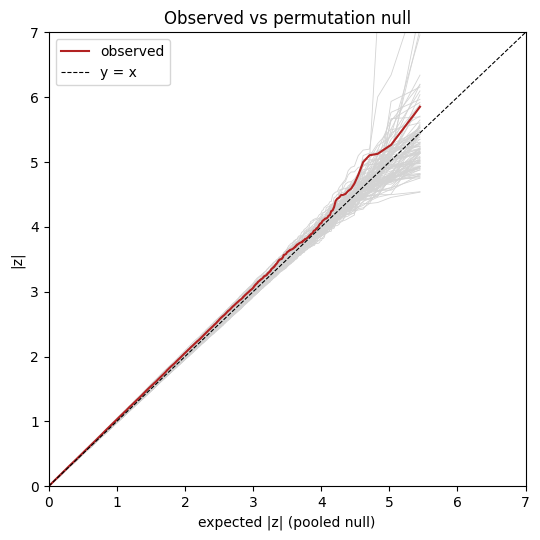

In [15]:
# Observed |z| sorted, against the pooled-null quantiles at the same probabilities
obs_sorted = np.sort(zabs[ok])
n = len(obs_sorted)
probs = (np.arange(1, n + 1) - 0.5) / n
null_q = null_abs[(probs * len(null_abs)).astype(int)]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
for b in range(100):                                          # 100 shuffled datasets
    zb = np.sort(np.abs(null_z[b])[np.isfinite(null_z[b])])
    ax.plot(null_q, zb, color="lightgrey", lw=0.6)
ax.plot(null_q, obs_sorted, color="firebrick", lw=1.5, label="observed")
ax.plot([0, 7], [0, 7], "k--", lw=0.8, label="y = x")
ax.set(xlabel="expected |z| (pooled null)", ylabel="|z|", xlim=(0, 7), ylim=(0, 7),
       title="Observed vs permutation null")
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "04_qq_observed_vs_null.png", dpi=150)
plt.show()

# 6. Power analysis 

In [16]:
T_fwer = np.percentile(maxabs_null, 95)    # 95th percentile of the strongest null result
T_cand = 4.4                               # about the level of the 15 candidate hits

n_spike = 300
spike_genes = rng.choice(len(universe), n_spike, replace=False)     # positions in the universe

def power_at(delta, axis="wPC1"):
    """|z| of the spiked genes after adding an effect of size delta to every family."""
    B = np.full((len(universe), len(strata)), np.nan); S = np.full_like(B, np.nan)
    for j, s in enumerate(strata):
        f = fam[s]; x = xobs[axis][s]
        xr = x - f["Q"] @ (f["Q"].T @ x); xr = xr / xr.std()          # covariate-adjusted axis, unit SD
        Yr = f["Yr"].copy()
        in_f = np.isin(f["pos"], spike_genes)                           # spiked genes tested in this family
        Yr[:, in_f] += delta * np.outer(xr, Yr[:, in_f].std(0))        # effect = delta x gene's residual SD
        B[f["pos"], j], S[f["pos"], j] = fit_fast({**f, "Yr": Yr}, x)
    z = meta(pd.DataFrame(B, index=universe, columns=strata),
             pd.DataFrame(S, index=universe, columns=strata))["z"].values
    return np.abs(z[spike_genes])

rows = []
for d in [0, 0.1, 0.2, 0.3, 0.4, 0.5]:
    za = power_at(d)
    rows.append({"delta": d, "median_abs_z": np.median(za),
                 f"power |z|>{T_cand}": (za > T_cand).mean(),
                 f"power |z|>{T_fwer:.2f} (FWER 5%)": (za > T_fwer).mean()})
power = pd.DataFrame(rows).round(2)
power.to_csv(OUT / "power_spike_in.csv", index=False)
power

,delta,median_abs_z,power |z|>4.4,power |z|>6.71 (FWER 5%)
0,0.0,0.76,0.00,0.00
1,0.1,2.22,0.04,0.00
2,0.2,4.34,0.48,0.03
3,0.3,6.48,0.89,0.44
4,0.4,8.64,0.98,0.84
5,0.5,10.82,0.99,0.94


# 7. Gene z-scores 
Using the same model, we run on each of the 19 within-family features instead of the PCs. Used in notebook 05 to link genes back to interpretable features. 

In [17]:
feats = pd.read_csv(MORPH / "morph_features_within.csv", index_col=0).loc[cells]

fz = {}
for name in feats.columns:
    x = {s: feats.loc[fam[s]["idx"], name].values for s in strata}
    fz[name] = run_axis(x)["z"]
fz = pd.DataFrame(fz)
fz.to_csv(OUT / "meta_feature_z.csv")
print(fz.shape)

(13934, 19)
